# Entrenamiento U-Net — muestra (Ruta A)

## 1. Configuración

In [1]:
import os, glob, re, json, random
import numpy as np, pandas as pd, rasterio, torch
import matplotlib.pyplot as plt
import segmentation_models_pytorch as smp
from scipy.ndimage import zoom
from torch.utils.data import Dataset, DataLoader, Sampler

BASE = r"C:\Datos\MachineLearning"
os.chdir(BASE)

RAIZ = "muestra"
SALIDA = "datos_muestra"
T = 256
ENCODERS = ["resnet34", "vgg19", "efficientnet-b0", "mobilenet_v2"]
MAX_EPOCAS = 15
PACIENCIA = 5
LOTE = 8
SEMILLA = 42
DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"

EVENTOS_KS = {1111002: "chad", 1111003: "yibuti", 1111004: "harvey", 1111005: "madagascar_1", 1111006: "madagascar_2"}
EVENTOS_VAL = {"madagascar_1", "madagascar_2", "20210319_PortMacquarie", "20210324_Sydney", "20220302_Coraki", "20220705_Sydney"}

os.makedirs(SALIDA, exist_ok=True)
DISPOSITIVO

'cuda'

## 2. Lectura y validación de archivos

In [2]:
def leer(ruta):
    with rasterio.open(ruta) as s:
        return s.read().astype("float32")

col = sorted(glob.glob(f"{RAIZ}/sen1floods11_colombia/WeaklyLabeled/S1Weak/*_S1Weak.tif"))
ks = sorted(os.path.dirname(f) for f in glob.glob(f"{RAIZ}/kurosiwo/**/info.json", recursive=True))
us = sorted(glob.glob(f"{RAIZ}/urbansarfloods/urban_sar_floods/*/SAR/*_SAR.tif"))

def etiqueta_colombia(ruta):
    return ruta.replace("S1Weak", "S1OtsuLabelWeak")

def gt_urbansar(ruta):
    return os.path.join(os.path.dirname(os.path.dirname(ruta)), "GT", os.path.basename(ruta).replace("_SAR.tif", "_GT.tif"))

def capa(p, clave):
    f = glob.glob(f"{p}/{clave}_*.tif")
    return leer(f[0])[0] if f else None

problemas = []
for r in col:
    if not os.path.exists(etiqueta_colombia(r)): problemas.append((r, "sin etiqueta"))
    elif leer(r).shape != (2, 512, 512): problemas.append((r, "forma"))
for p in ks:
    for k in ["MS1_IVV", "MS1_IVH", "MK0_MLU", "MK0_MNA"]:
        if not glob.glob(f"{p}/{k}_*.tif"): problemas.append((p, f"falta {k}"))
for r in us:
    if not os.path.exists(gt_urbansar(r)): problemas.append((r, "sin GT"))
    elif leer(r).shape != (8, 512, 512): problemas.append((r, "forma"))

ks = [p for p in ks if not any(p == q for q, _ in problemas)]
print(f"Colombia: {len(col)} · Kuro Siwo: {len(ks)} · UrbanSAR: {len(us)} · problemas: {len(problemas)}")
problemas

Colombia: 12 · Kuro Siwo: 40 · UrbanSAR: 30 · problemas: 0


[]

## 3. Funciones de preprocesamiento

In [3]:
def a_db(x):
    return 10 * np.log10(np.clip(x, 1e-6, None))

def limpiar(img):
    return np.clip(np.nan_to_num(img, nan=-30), -30, 5).astype("float32")

def guardar_parches(img, lab, val, dataset, evento, nombre):
    carpeta = f"{SALIDA}/parches/{dataset}/{evento}"
    os.makedirs(carpeta, exist_ok=True)
    H, W = lab.shape
    ph, pw = (-H) % T, (-W) % T
    img = np.pad(img, ((0, 0), (0, ph), (0, pw)), constant_values=-30)
    lab = np.pad(lab.astype("uint8"), ((0, ph), (0, pw)))
    val = np.pad(val.astype("uint8"), ((0, ph), (0, pw)))
    filas = []
    for i in range(0, img.shape[1], T):
        for j in range(0, img.shape[2], T):
            v = val[i:i+T, j:j+T]
            if v.mean() < 0.2:
                continue
            l = lab[i:i+T, j:j+T] * v
            ruta = f"{carpeta}/{nombre}_{i}_{j}.npz"
            np.savez_compressed(ruta, img=img[:, i:i+T, j:j+T], lab=l, val=v)
            filas.append(dict(ruta=ruta, dataset=dataset, evento=evento, frac_valida=v.mean(), frac_agua=l.sum() / v.sum()))
    return filas

indice = []

## 4. Sen1Floods11 Colombia

In [4]:
for r in col:
    img = leer(r)
    etq = leer(etiqueta_colombia(r))[0]
    val = np.isfinite(img).all(0) & (etq != -1)
    nombre = os.path.basename(r).replace("_S1Weak.tif", "")
    indice += guardar_parches(limpiar(img), etq == 1, val, "colombia", "colombia", nombre)
len(indice)

48

## 5. Kuro Siwo

In [5]:
for p in ks:
    act = json.load(open(f"{p}/info.json"))["actid"]
    vv, vh = capa(p, "MS1_IVV"), capa(p, "MS1_IVH")
    mlu, mna = capa(p, "MK0_MLU"), capa(p, "MK0_MNA")
    img = limpiar(a_db(np.stack([vv, vh])))
    val = (mna == 1) & (mlu != 3) & (vv > 0) & (vh > 0)
    indice += guardar_parches(img, np.isin(mlu, [1, 2]), val, "kurosiwo", EVENTOS_KS[act], os.path.basename(p))
len(indice)

88

## 6. UrbanSARFloods

In [6]:
for r in us:
    a = leer(r)
    gt = leer(gt_urbansar(r))[0]
    img = np.stack([a[7], a[6]])
    val = np.isfinite(img).all(0).astype("uint8")
    img = zoom(limpiar(img), (1, 2, 2), order=1)
    lab = zoom(np.isin(gt, [1, 2]).astype("uint8"), 2, order=0)
    val = zoom(val, 2, order=0)
    nombre = os.path.basename(r).replace("_SAR.tif", "")
    evento = re.match(r"\d+_[A-Za-z]+", nombre).group()
    indice += guardar_parches(img, lab, val, "urbansar", evento, nombre)
len(indice)

538

## 7. Índice de parches

In [7]:
indice = pd.DataFrame(indice)
indice["con_agua"] = indice.frac_agua > 0.01
indice.groupby(["dataset", "evento"]).agg(parches=("ruta", "size"), con_agua=("con_agua", "sum"), agua_media=("frac_agua", "mean"), valido_medio=("frac_valida", "mean")).round(3)

parches  con_agua  agua_media  valido_medio
dataset  evento                                                             
colombia colombia                     48        35       0.158         1.000
kurosiwo chad                          6         5       0.067         0.633
         harvey                       16        11       0.098         0.704
         madagascar_1                  6         4       0.254         0.766
         madagascar_2                  6         4       0.361         0.742
         yibuti                        6         5       0.078         0.673
urbansar 20160419_Houston             22         4       0.011         0.943
         20161011_Lumberton           32         8       0.014         1.000
         20170830_Houston             24        13       0.069         0.942
         20180508_Somalia             32         7       0.020         0.971
         20190320_Beira               32         8       0.011         1.000
         20190329_Iran                32        20       0.112         1.000
         20190502_Canada              32        18       0.109         1.000
         20191012_Japan               32         8       0.032         1.000
         20210319_PortMacquarie       29         9       0.018         0.958
         20210324_Sydney              32        23       0.190         1.000
         20220302_Coraki              27        25       0.378         0.952
         20220705_Sydney              32        14       0.061         1.000
         20221013_Niger               32        18       0.123         1.000
         20230805_Hebei               28        14       0.048         0.939
         20231114_Beledweyne          32        25       0.232         1.000

## 8. Partición por eventos

In [8]:
indice["particion"] = np.where(indice.evento.isin(EVENTOS_VAL), "val", "train")
particion = {k: sorted(g.evento.unique().tolist()) for k, g in indice.groupby("particion")}
json.dump(particion, open(f"{SALIDA}/particion.json", "w"), indent=2)
indice.to_csv(f"{SALIDA}/indice.csv", index=False)
print(indice.groupby("particion").agg(parches=("ruta", "size"), con_agua=("con_agua", "sum")))
particion

           parches  con_agua
particion                   
train          406       199
val            132        79


{'train': ['20160419_Houston',
  '20161011_Lumberton',
  '20170830_Houston',
  '20180508_Somalia',
  '20190320_Beira',
  '20190329_Iran',
  '20190502_Canada',
  '20191012_Japan',
  '20221013_Niger',
  '20230805_Hebei',
  '20231114_Beledweyne',
  'chad',
  'colombia',
  'harvey',
  'yibuti'],
 'val': ['20210319_PortMacquarie',
  '20210324_Sydney',
  '20220302_Coraki',
  '20220705_Sydney',
  'madagascar_1',
  'madagascar_2']}

## 9. Estadísticas de normalización (solo Train)

In [9]:
s, s2, n = np.zeros(2), np.zeros(2), 0
for r in indice.query("particion == 'train'").ruta:
    d = np.load(r)
    x = d["img"][:, d["val"] == 1].astype("float64")
    s += x.sum(1)
    s2 += (x ** 2).sum(1)
    n += x.shape[1]
media = s / n
std = np.sqrt(s2 / n - media ** 2)
stats = {"canales": ["VV", "VH"], "media": media.tolist(), "std": std.tolist()}
json.dump(stats, open(f"{SALIDA}/stats.json", "w"), indent=2)
MEDIA = np.array(stats["media"], dtype="float32")[:, None, None]
STD = np.array(stats["std"], dtype="float32")[:, None, None]
stats

{'canales': ['VV', 'VH'],
 'media': [-9.857488425866626, -15.688506912224408],
 'std': [5.022871708383476, 4.674222484255708]}

## 10. Visualización de parches

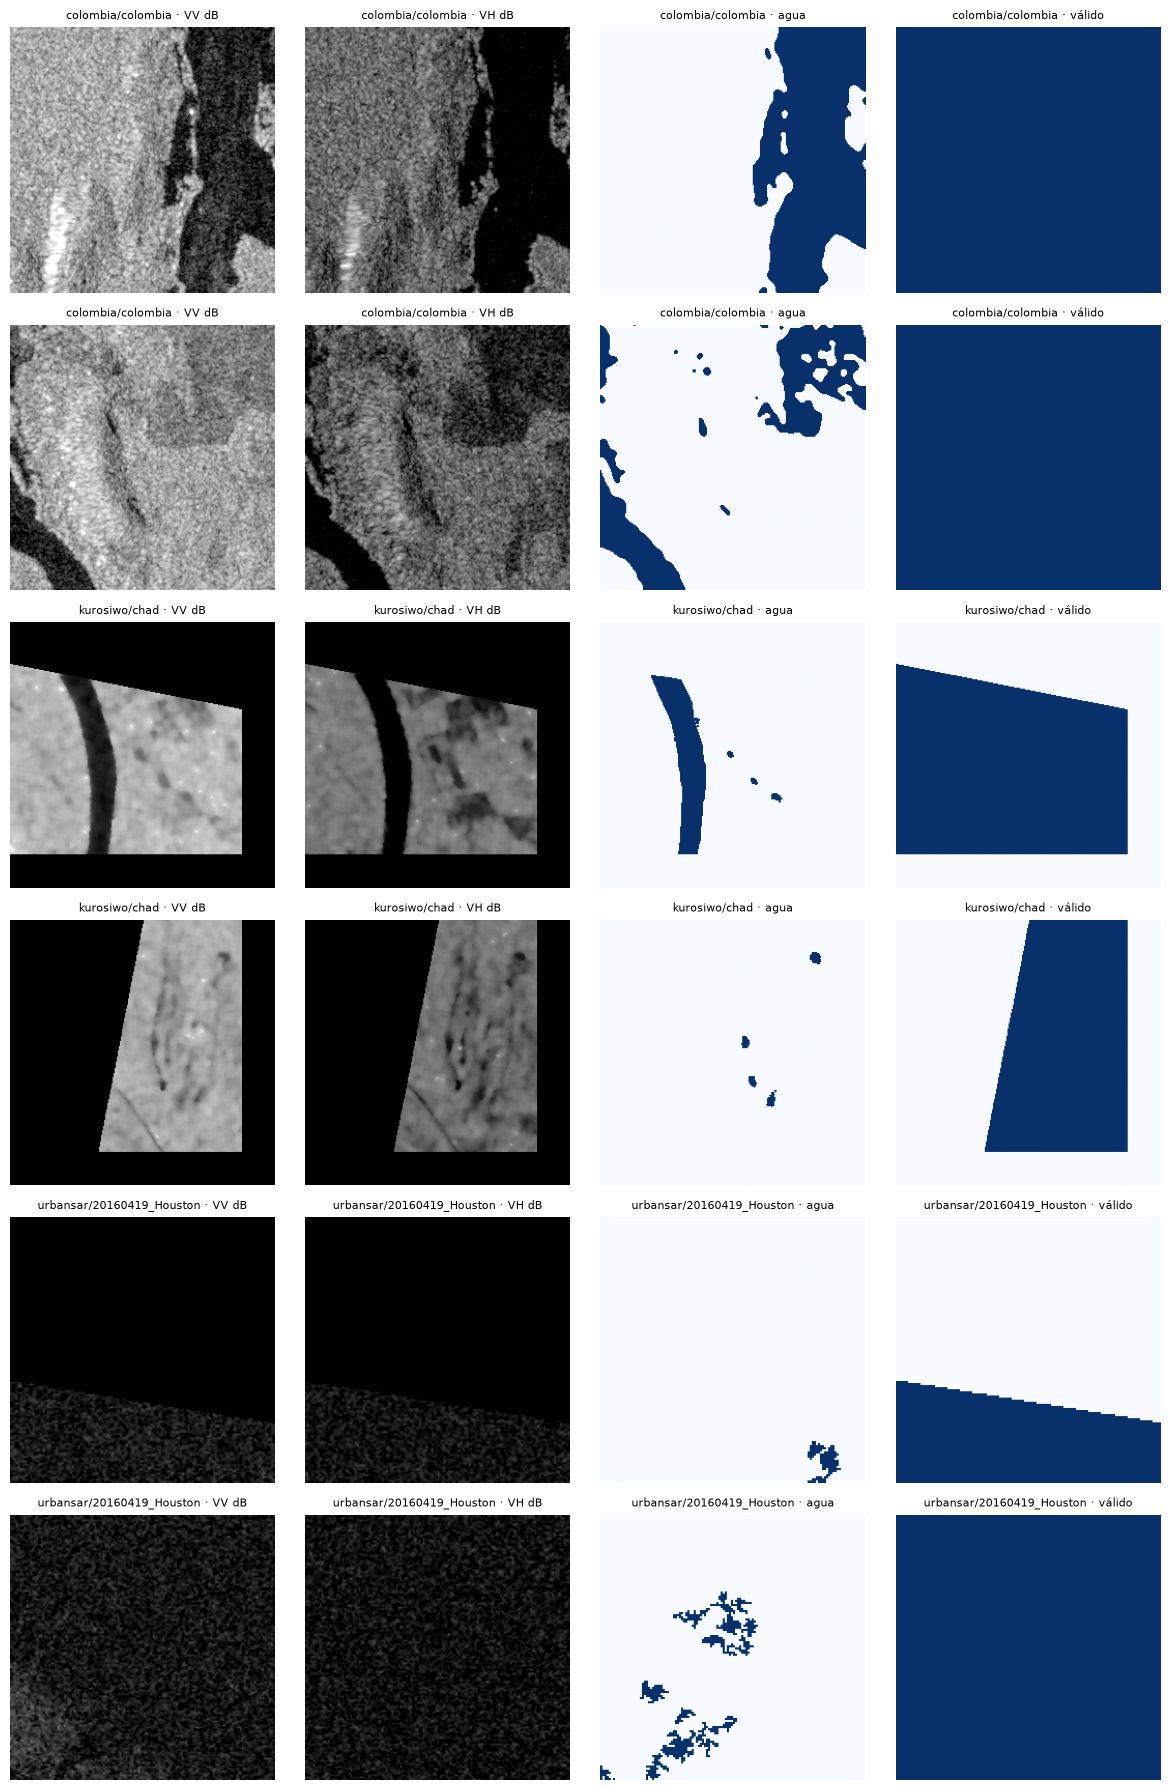

In [10]:
ejemplos = indice[indice.con_agua].groupby("dataset").head(2)
fig, ejes = plt.subplots(len(ejemplos), 4, figsize=(12, 3 * len(ejemplos)))
for fila, (_, e) in zip(ejes, ejemplos.iterrows()):
    d = np.load(e.ruta)
    for ax, x, t in zip(fila, [d["img"][0], d["img"][1], d["lab"], d["val"]], ["VV dB", "VH dB", "agua", "válido"]):
        ax.imshow(x, cmap="gray" if "dB" in t else "Blues", vmin=(-25 if "dB" in t else 0), vmax=(0 if "dB" in t else 1))
        ax.set_title(f"{e.dataset}/{e.evento} · {t}", fontsize=8)
        ax.axis("off")
plt.tight_layout()

## 11. Dataset y lotes balanceados

In [11]:
class Parches(Dataset):
    def __init__(self, rutas, aumentar):
        self.rutas, self.aumentar = list(rutas), aumentar
    def __len__(self):
        return len(self.rutas)
    def __getitem__(self, k):
        d = np.load(self.rutas[k])
        arr = [(d["img"] - MEDIA) / STD, d["lab"][None], d["val"][None]]
        if self.aumentar:
            g = random.randint(0, 3)
            arr = [np.rot90(a, g, axes=(1, 2)) for a in arr]
            if random.random() < 0.5:
                arr = [a[:, :, ::-1] for a in arr]
            if random.random() < 0.5:
                arr = [a[:, ::-1, :] for a in arr]
        return tuple(torch.from_numpy(np.ascontiguousarray(a, dtype="float32")) for a in arr)

class LotesBalanceados(Sampler):
    def __init__(self, con_agua, n_total, lote):
        self.con_agua, self.n_total, self.lote = list(con_agua), n_total, lote
    def __len__(self):
        return max(self.n_total // self.lote, 1)
    def __iter__(self):
        mitad = self.lote // 2
        for _ in range(len(self)):
            yield random.choices(self.con_agua, k=mitad) + random.sample(range(self.n_total), self.lote - mitad)

train = indice.query("particion == 'train'").reset_index(drop=True)
val = indice.query("particion == 'val'").reset_index(drop=True)
ds_train = Parches(train.ruta, aumentar=True)
ds_val = Parches(val.ruta, aumentar=False)
cargador_val = DataLoader(ds_val, batch_size=LOTE, shuffle=False)
img, lab, v = next(iter(DataLoader(ds_train, batch_sampler=LotesBalanceados(np.flatnonzero(train.con_agua), len(train), LOTE))))
img.shape, lab.shape, v.shape, (lab.flatten(1).sum(1) > 0).tolist()

(torch.Size([8, 2, 256, 256]),
 torch.Size([8, 1, 256, 256]),
 torch.Size([8, 1, 256, 256]),
 [True, True, True, True, True, True, True, False])

## 12. Pérdida y métricas

In [12]:
def perdida(logits, lab, val):
    p = torch.sigmoid(logits)
    bce = torch.nn.functional.binary_cross_entropy_with_logits(logits, lab, reduction="none")
    bce = (bce * val).sum() / val.sum().clamp(min=1)
    inter = (p * lab * val).sum()
    dice = 1 - (2 * inter + 1) / (((p + lab) * val).sum() + 1)
    return bce + dice

def metricas(tp, fp, fn, tn):
    return {"IoU": tp / max(tp + fp + fn, 1), "Dice": 2 * tp / max(2 * tp + fp + fn, 1),
            "Precision": tp / max(tp + fp, 1), "Recall": tp / max(tp + fn, 1),
            "Accuracy": (tp + tn) / max(tp + fp + fn + tn, 1)}

def evaluar(modelo, cargador):
    modelo.eval()
    c, total = np.zeros(4), 0.0
    with torch.no_grad():
        for img, lab, v in cargador:
            img, lab, v = img.to(DISPOSITIVO), lab.to(DISPOSITIVO), v.to(DISPOSITIVO)
            logits = modelo(img)
            total += perdida(logits, lab, v).item() * len(img)
            p, l, m = logits > 0, lab > 0.5, v > 0.5
            c += [(p & l & m).sum().item(), (p & ~l & m).sum().item(), (~p & l & m).sum().item(), (~p & ~l & m).sum().item()]
    return {"perdida_val": total / len(cargador.dataset), **metricas(*c)}

## 13. Entrenamiento de los 4 encoders

In [13]:
def fijar_semilla(s):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

os.makedirs(f"{SALIDA}/modelos", exist_ok=True)
resultados, historial = [], []
for enc in ENCODERS:
    fijar_semilla(SEMILLA)
    cargador_train = DataLoader(ds_train, batch_sampler=LotesBalanceados(np.flatnonzero(train.con_agua), len(train), LOTE))
    modelo = smp.Unet(enc, encoder_weights="imagenet", in_channels=2, classes=1).to(DISPOSITIVO)
    opt = torch.optim.Adam(modelo.parameters(), lr=1e-4)
    mejor, sin_mejora = None, 0
    for epoca in range(1, MAX_EPOCAS + 1):
        modelo.train()
        suma = 0.0
        for img, lab, v in cargador_train:
            img, lab, v = img.to(DISPOSITIVO), lab.to(DISPOSITIVO), v.to(DISPOSITIVO)
            opt.zero_grad()
            l = perdida(modelo(img), lab, v)
            l.backward()
            opt.step()
            suma += l.item()
        m = evaluar(modelo, cargador_val)
        historial.append({"encoder": enc, "epoca": epoca, "perdida_train": suma / len(cargador_train), **m})
        print(f"{enc:16s} época {epoca:2d} · pérdida train {suma / len(cargador_train):.3f} · val {m['perdida_val']:.3f} · IoU {m['IoU']:.3f} · Dice {m['Dice']:.3f}")
        if mejor is None or m["IoU"] > mejor["IoU"]:
            mejor, sin_mejora = {"encoder": enc, "epoca": epoca, **m}, 0
            torch.save(modelo.state_dict(), f"{SALIDA}/modelos/unet_{enc}.pt")
        else:
            sin_mejora += 1
            if sin_mejora >= PACIENCIA:
                break
    resultados.append(mejor)

historial = pd.DataFrame(historial)
historial.to_csv(f"{SALIDA}/historial.csv", index=False)

resnet34         época  1 · pérdida train 1.372 · val 1.078 · IoU 0.581 · Dice 0.735


resnet34         época  2 · pérdida train 1.132 · val 0.914 · IoU 0.656 · Dice 0.792


resnet34         época  3 · pérdida train 1.066 · val 0.854 · IoU 0.680 · Dice 0.810


resnet34         época  4 · pérdida train 0.943 · val 0.832 · IoU 0.674 · Dice 0.805


resnet34         época  5 · pérdida train 0.924 · val 0.750 · IoU 0.762 · Dice 0.865


...

mobilenet_v2     época 11 · pérdida train 0.680 · val 0.516 · IoU 0.748 · Dice 0.856


mobilenet_v2     época 12 · pérdida train 0.687 · val 0.609 · IoU 0.517 · Dice 0.681


mobilenet_v2     época 13 · pérdida train 0.632 · val 0.487 · IoU 0.730 · Dice 0.844


mobilenet_v2     época 14 · pérdida train 0.611 · val 0.532 · IoU 0.649 · Dice 0.787


mobilenet_v2     época 15 · pérdida train 0.588 · val 0.557 · IoU 0.619 · Dice 0.765


## 14. Comparación y selección del encoder

In [14]:
resultados = pd.DataFrame(resultados).sort_values("IoU", ascending=False).reset_index(drop=True)
resultados.to_csv(f"{SALIDA}/resultados_val.csv", index=False)
MEJOR = resultados.encoder[0]
print("Mejor encoder por IoU en Val:", MEJOR)
resultados.round(4)

Mejor encoder por IoU en Val: vgg19


,encoder,epoca,perdida_val,IoU,Dice,Precision,Recall,Accuracy
0,vgg19,7,0.5439,0.7909,0.8833,0.8566,0.9116,0.9603
1,resnet34,5,0.7497,0.7625,0.8652,0.8496,0.8814,0.9547
2,efficientnet-b0,3,0.8332,0.7572,0.8618,0.8026,0.9305,0.9508
3,mobilenet_v2,11,0.5158,0.7482,0.8560,0.9029,0.8137,0.9548


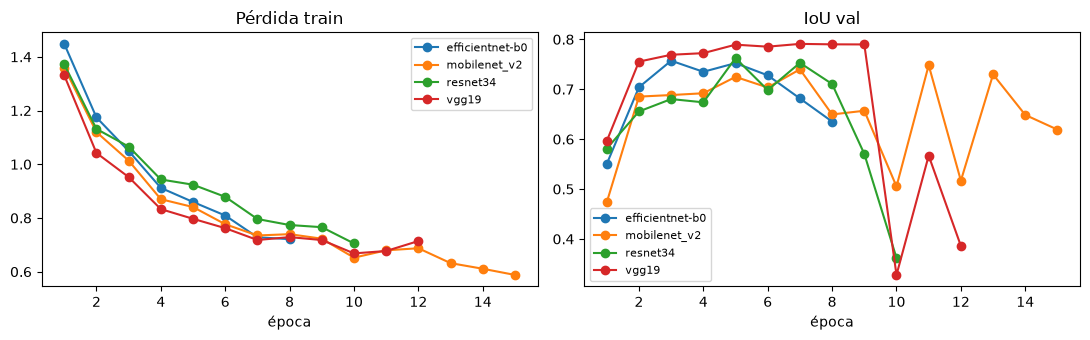

In [15]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5))
for enc, g in historial.groupby("encoder"):
    ejes[0].plot(g.epoca, g.perdida_train, marker="o", label=enc)
    ejes[1].plot(g.epoca, g.IoU, marker="o", label=enc)
ejes[0].set_title("Pérdida train")
ejes[1].set_title("IoU val")
for ax in ejes:
    ax.set_xlabel("época")
    ax.legend(fontsize=8)
plt.tight_layout()

## 15. Predicciones del mejor modelo en Val

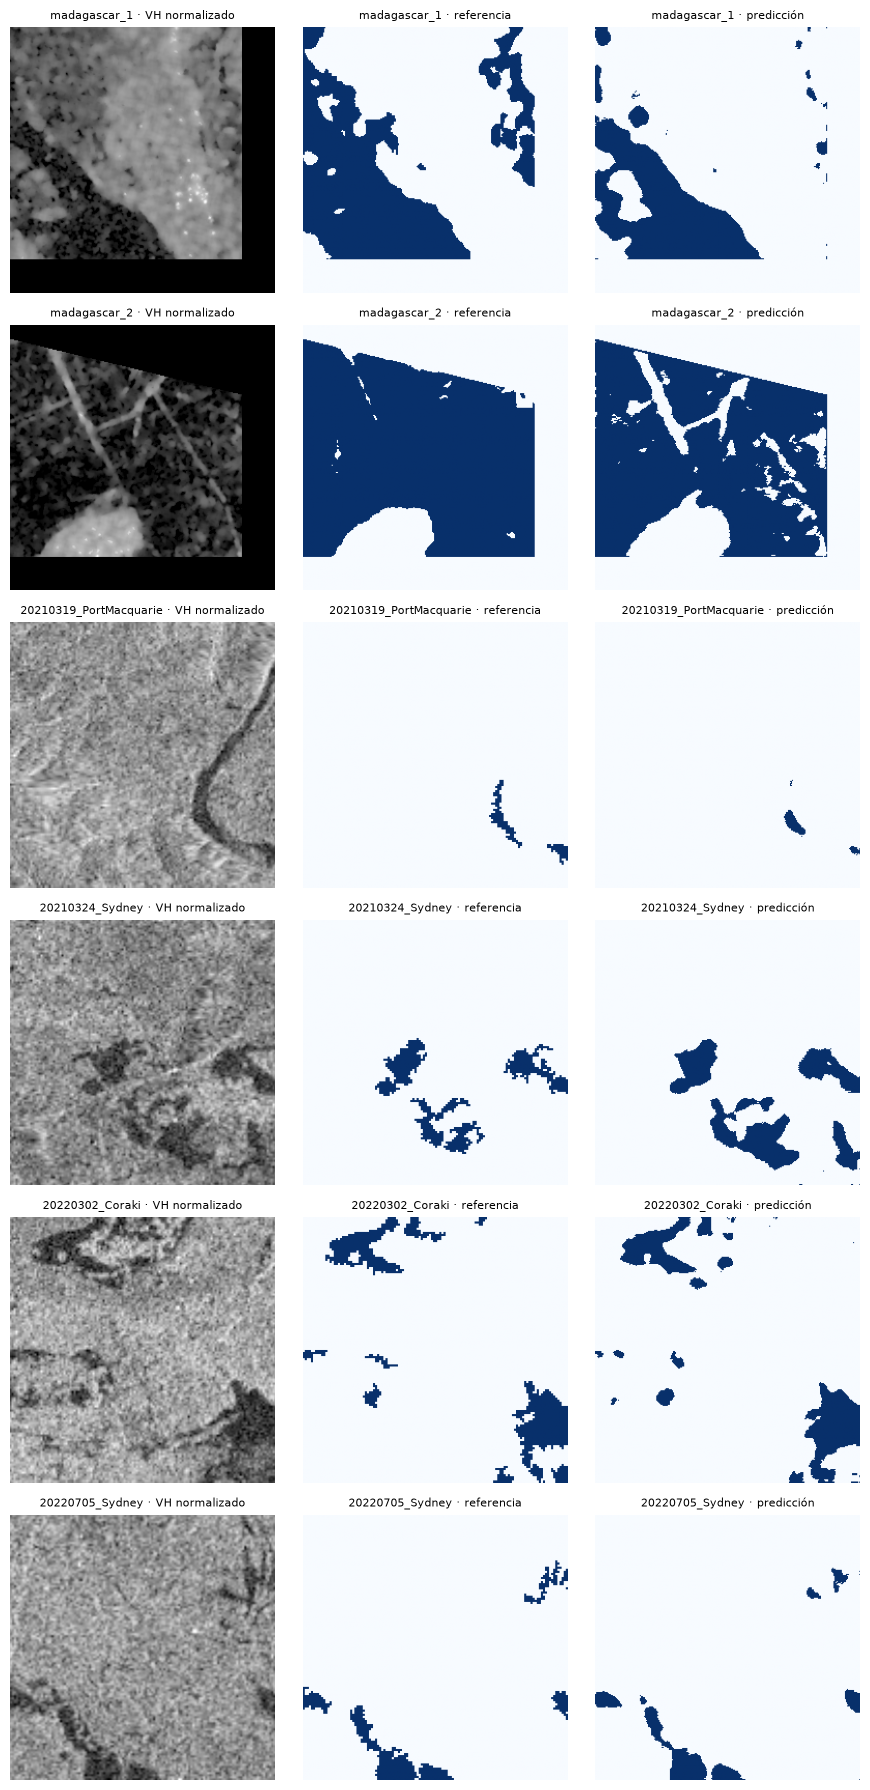

In [16]:
modelo = smp.Unet(MEJOR, encoder_weights=None, in_channels=2, classes=1).to(DISPOSITIVO)
modelo.load_state_dict(torch.load(f"{SALIDA}/modelos/unet_{MEJOR}.pt", map_location=DISPOSITIVO))
modelo.eval()
muestras = val[val.con_agua].groupby("evento").head(1).head(6)
fig, ejes = plt.subplots(len(muestras), 3, figsize=(9, 3 * len(muestras)))
for fila, (k, e) in zip(np.atleast_2d(ejes), muestras.iterrows()):
    img, lab, v = ds_val[k]
    with torch.no_grad():
        p = torch.sigmoid(modelo(img[None].to(DISPOSITIVO)))[0, 0].cpu().numpy()
    for ax, x, t in zip(fila, [img[1], lab[0], (p >= 0.5) * v[0].numpy()], ["VH normalizado", "referencia", "predicción"]):
        ax.imshow(x, cmap="gray" if t.startswith("VH") else "Blues")
        ax.set_title(f"{e.evento} · {t}", fontsize=8)
        ax.axis("off")
plt.tight_layout()

## 16. Predicción sobre un GeoTIFF

In [17]:
from rasterio.warp import reproject, Resampling

HAND = sorted(glob.glob("test_lima/auxiliares/glo30_hand/*.tif"))

def a_grilla(rutas, perfil, remuestreo=Resampling.bilinear):
    out = np.full((perfil["height"], perfil["width"]), np.nan, "float32")
    for r in rutas:
        tmp = np.full_like(out, np.nan)
        with rasterio.open(r) as s:
            reproject(rasterio.band(s, 1), tmp, dst_transform=perfil["transform"], dst_crs=perfil["crs"], resampling=remuestreo, dst_nodata=np.nan)
        out = np.where(np.isnan(out), tmp, out)
    return out

def predecir_ventanas(modelo, x, paso=128):
    _, H, W = x.shape
    ph, pw = max(T - H, 0) + (-max(H, T)) % paso, max(T - W, 0) + (-max(W, T)) % paso
    x = np.pad(x, ((0, 0), (0, ph), (0, pw)), mode="reflect")
    suma, n = np.zeros(x.shape[1:]), np.zeros(x.shape[1:])
    with torch.no_grad():
        for i in range(0, x.shape[1] - T + 1, paso):
            for j in range(0, x.shape[2] - T + 1, paso):
                v = torch.from_numpy(np.ascontiguousarray(x[None, :, i:i+T, j:j+T])).to(DISPOSITIVO)
                suma[i:i+T, j:j+T] += torch.sigmoid(modelo(v))[0, 0].cpu().numpy()
                n[i:i+T, j:j+T] += 1
    return (suma / np.maximum(n, 1))[:H, :W]

def predecir_tif(ruta, vv=1, vh=2, lineal=False, umbral=0.5, referencia=None, hand_max=None, salida=f"{SALIDA}/predicciones"):
    with rasterio.open(ruta) as s:
        img = s.read([vv, vh]).astype("float32")
        perfil = s.profile
    if lineal:
        img = a_db(img)
    valido = np.isfinite(img).all(0) & (img != 0).all(0)
    x = ((limpiar(img) - MEDIA) / STD).astype("float32")
    prob = predecir_ventanas(modelo, x)
    permitido = ~(a_grilla(HAND, perfil) >= hand_max) if hand_max is not None else np.ones_like(valido)
    agua = ((prob >= umbral) & valido & permitido).astype("uint8")
    agua[~valido] = 255

    os.makedirs(salida, exist_ok=True)
    nombre = os.path.splitext(os.path.basename(ruta))[0]
    perfil.update(count=1, dtype="uint8", nodata=255, compress="deflate")
    with rasterio.open(f"{salida}/{nombre}_agua.tif", "w", **perfil) as d:
        d.write(agua, 1)
    perfil.update(dtype="float32", nodata=-1)
    with rasterio.open(f"{salida}/{nombre}_prob.tif", "w", **perfil) as d:
        d.write(np.where(valido, prob, -1).astype("float32"), 1)

    res = {"imagen": nombre, "agua_%": 100 * (agua == 1).sum() / max(valido.sum(), 1)}
    titulo = "agua" if hand_max is None else f"agua (HAND<{hand_max} m)"
    paneles = [(np.ma.masked_where(~valido, img[1]), "VH (dB)", "gray", -25, 0),
               (np.ma.masked_where(~valido, prob), "probabilidad", "viridis", 0, 1),
               (np.ma.masked_equal(agua, 255), titulo, "Blues", 0, 1)]
    if referencia is not None:
        ref = leer(referencia)[0] if isinstance(referencia, str) else referencia
        m = valido & (ref != -1)
        p, r = agua[m] == 1, ref[m] == 1
        res.update(metricas((p & r).sum(), (p & ~r).sum(), (~p & r).sum(), (~p & ~r).sum()))
        paneles.append((np.ma.masked_where(ref == -1, ref == 1), "referencia", "Blues", 0, 1))

    r = max(1, max(agua.shape) // 1500)
    fig, ejes = plt.subplots(1, len(paneles), figsize=(4 * len(paneles), 4))
    for ax, (z, t, cmap, vmin, vmax) in zip(ejes, paneles):
        ax.imshow(z[::r, ::r], cmap=cmap, vmin=vmin, vmax=vmax)
        ax.set_title(f"{nombre} · {t}", fontsize=8)
        ax.axis("off")
    plt.tight_layout()
    plt.show()
    return res

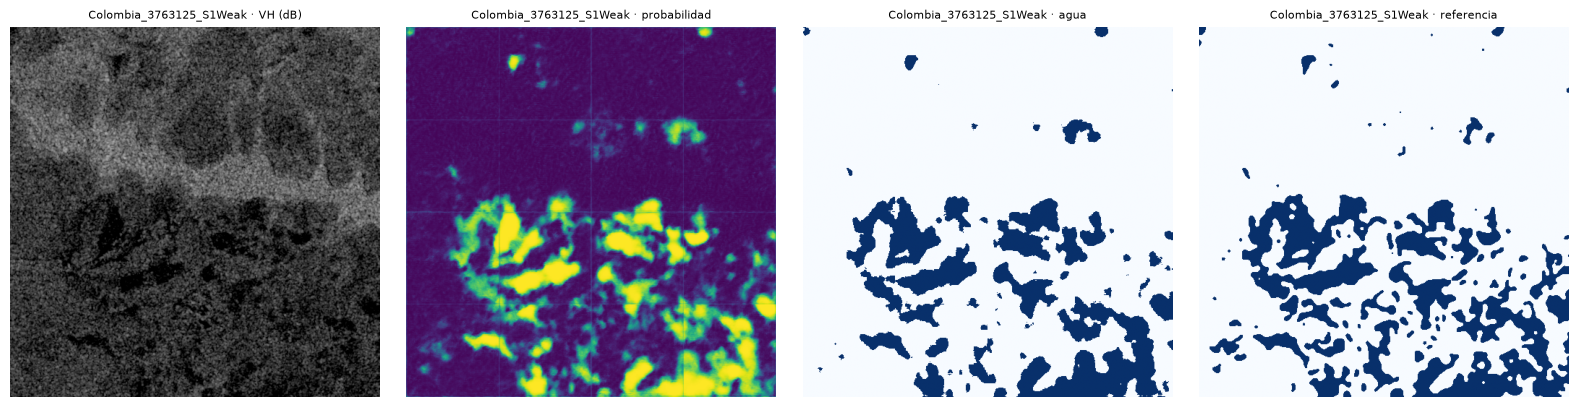

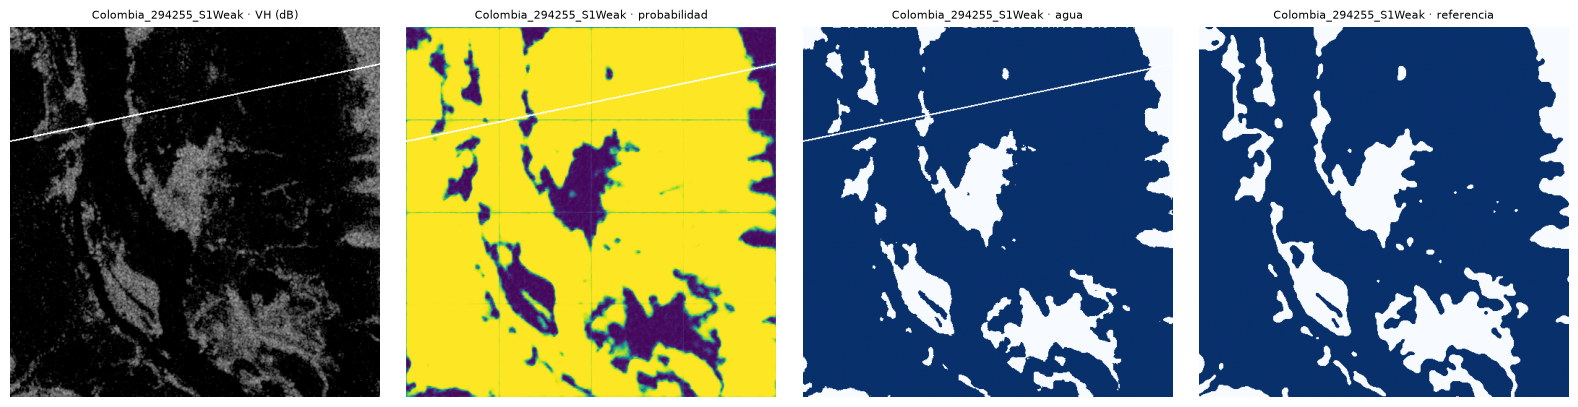

,imagen,agua_%,IoU,Dice,Precision,Recall,Accuracy
0,Colombia_3763125_S1Weak,16.438,0.691,0.817,0.878,0.765,0.936
1,Colombia_294255_S1Weak,83.911,0.939,0.969,0.940,0.999,0.949


In [18]:
C = "sen1floods11_colombia/WeaklyLabeled"
pruebas = ["Colombia_3763125", "Colombia_294255"]
pd.DataFrame([predecir_tif(f"{C}/S1Weak/{p}_S1Weak.tif", referencia=f"{C}/S1OtsuLabelWeak/{p}_S1OtsuLabelWeak.tif") for p in pruebas]).round(3)

## 17. Lima Norte 2017 vs EMSN038

In [19]:
import geopandas as gpd
from rasterio.features import rasterize

LIMA = "test_lima/procesadas"
gdb = "test_lima/emsn038_2017/EMSN038_UTM18S_v0.gdb"
agua_ems = pd.concat([gpd.read_file(gdb, layer=c) for c in ["Potential_Maximum_flood", "Riverbank"]])
zona = gpd.read_file(gdb, layer="EMSN038_AOI").overlay(gpd.read_file(gdb, layer="Footprints"), how="intersection")
with rasterio.open(f"{LIMA}/lima_2017_0317.tif") as s:
    forma, tr, crs = (s.height, s.width), s.transform, s.crs
    vh_2017 = s.read(2)
ref_2017 = rasterize(((g, 1) for g in agua_ems.to_crs(crs).geometry.force_2d()), forma, transform=tr, fill=0).astype("int16")
evaluable = rasterize(((g, 1) for g in zona.to_crs(crs).geometry.force_2d()), forma, transform=tr, fill=0)
ref_2017[evaluable == 0] = -1
print(f"píxeles evaluables: {(ref_2017 != -1).sum():,} · agua EMSN038: {(ref_2017 == 1).sum():,}")

C:\Users\andre\AppData\Local\Programs\Python\Python313\Lib\site-packages\pyogrio\raw.py:200: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D MultiPolygon' is converted to 'MultiPolygon Z'
  return ogr_read(


píxeles evaluables: 24,161,602 · agua EMSN038: 135,819


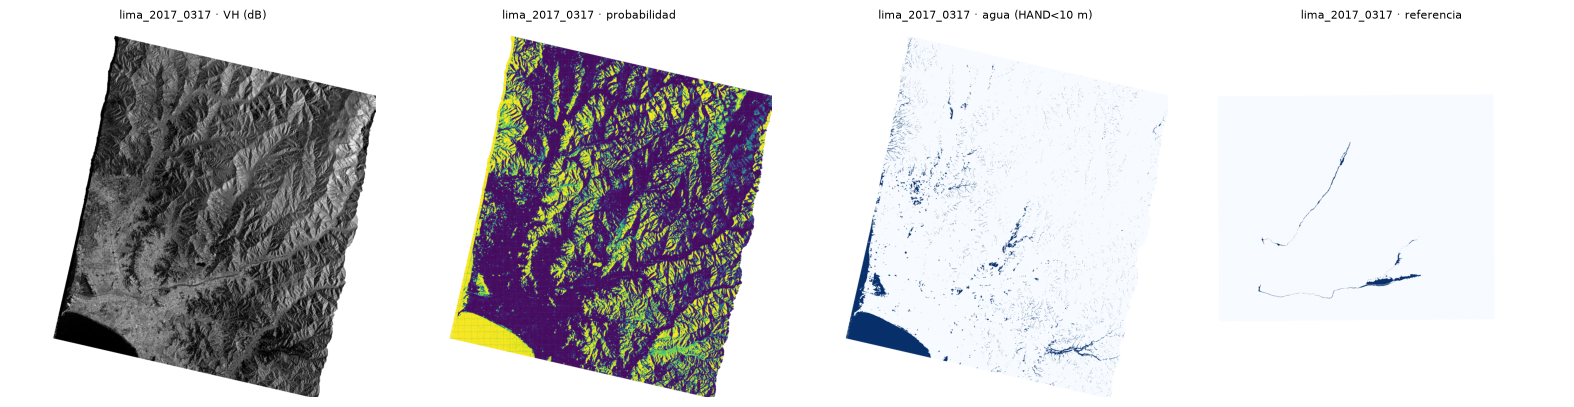

,metodo,agua_%,IoU,Dice,Precision,Recall,Accuracy
0,U-Net vgg19,28.309,0.002,0.003,0.002,0.063,0.711
1,U-Net vgg19 + HAND<10,4.260,0.009,0.018,0.010,0.063,0.951
2,Otsu VH (-17.4 dB),50.644,0.006,0.012,0.006,0.437,0.493
3,Otsu VH (-17.4 dB) + HAND<10,11.308,0.025,0.050,0.026,0.435,0.886


In [20]:
def otsu(x, bins=256):
    h, b = np.histogram(np.clip(x, -30, 5), bins=bins)
    c = (b[:-1] + b[1:]) / 2
    p = h / h.sum()
    w, mu = np.cumsum(p), np.cumsum(p * c)
    return c[np.nanargmax((mu[-1] * w - mu) ** 2 / (w * (1 - w) + 1e-12))]

predecir_tif(f"{LIMA}/lima_2017_0317.tif", referencia=ref_2017, hand_max=10)
with rasterio.open(f"{SALIDA}/predicciones/lima_2017_0317_prob.tif") as s:
    prob_2017, perfil_2017 = s.read(1), s.profile
hand_2017 = a_grilla(HAND, perfil_2017)
m = (prob_2017 >= 0) & (ref_2017 != -1)
x, h, r = np.clip(vh_2017[m], -30, 5), hand_2017[m] < 10, ref_2017[m] == 1
umbral_otsu = otsu(x)

def fila(metodo, p):
    return {"metodo": metodo, "agua_%": 100 * p.mean(), **metricas((p & r).sum(), (p & ~r).sum(), (~p & r).sum(), (~p & ~r).sum())}

pd.DataFrame([fila(f"U-Net {MEJOR}", prob_2017[m] >= 0.5),
              fila(f"U-Net {MEJOR} + HAND<10", (prob_2017[m] >= 0.5) & h),
              fila(f"Otsu VH ({umbral_otsu:.1f} dB)", x < umbral_otsu),
              fila(f"Otsu VH ({umbral_otsu:.1f} dB) + HAND<10", (x < umbral_otsu) & h)]).round(3)

## 18. Lima Sur 2023

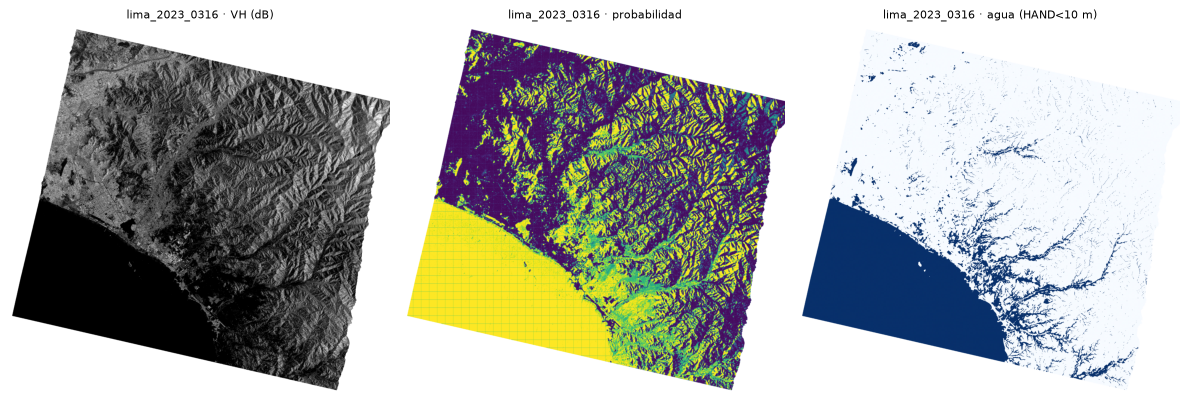

,imagen,agua_%
0,lima_2023_0316,25.298


In [21]:
pd.DataFrame([predecir_tif(f"{LIMA}/lima_2023_0316.tif", hand_max=10)]).round(3)

## 19. Detección de cambio (antes / después)

In [22]:
def leer_en_grilla(ruta, perfil, bandas=(1, 2)):
    out = np.zeros((len(bandas), perfil["height"], perfil["width"]), "float32")
    with rasterio.open(ruta) as s:
        for k, b in enumerate(bandas):
            reproject(rasterio.band(s, b), out[k], dst_transform=perfil["transform"], dst_crs=perfil["crs"],
                      resampling=Resampling.bilinear, src_nodata=0, dst_nodata=0)
    return out

def detectar_cambio(post, pre, hand_max=10, umbral=0.5, delta_db=-3, referencia=None, salida=f"{SALIDA}/predicciones"):
    with rasterio.open(post) as s:
        img_post, perfil = s.read([1, 2]).astype("float32"), s.profile
    img_pre = leer_en_grilla(pre, perfil)
    valido = (img_post != 0).all(0) & (img_pre != 0).all(0) & np.isfinite(img_post).all(0) & np.isfinite(img_pre).all(0)
    p_post = predecir_ventanas(modelo, ((limpiar(img_post) - MEDIA) / STD).astype("float32"))
    p_pre = predecir_ventanas(modelo, ((limpiar(img_pre) - MEDIA) / STD).astype("float32"))
    bajo = a_grilla(HAND, perfil) < hand_max
    dvh = img_post[1] - img_pre[1]
    capas = {f"U-Net después + HAND<{hand_max}": (p_post >= umbral) & bajo,
             f"U-Net cambio + HAND<{hand_max}": (p_post >= umbral) & (p_pre < umbral) & bajo,
             f"ΔVH<{delta_db} dB + HAND<{hand_max}": (dvh < delta_db) & bajo,
             f"U-Net cambio + ΔVH<{delta_db} dB + HAND<{hand_max}": (p_post >= umbral) & (p_pre < umbral) & (dvh < delta_db) & bajo}
    inundacion = list(capas.values())[1]

    nombre = os.path.splitext(os.path.basename(post))[0]
    os.makedirs(salida, exist_ok=True)
    perfil.update(count=1, dtype="uint8", nodata=255, compress="deflate")
    with rasterio.open(f"{salida}/{nombre}_inundacion.tif", "w", **perfil) as d:
        d.write(np.where(valido, inundacion, 255).astype("uint8"), 1)

    ref = None if referencia is None else (leer(referencia)[0] if isinstance(referencia, str) else referencia)
    m = valido if ref is None else valido & (ref != -1)
    filas = []
    for metodo, capa_ in capas.items():
        p = capa_[m]
        f = {"metodo": metodo, "agua_%": 100 * p.mean()}
        if ref is not None:
            r = ref[m] == 1
            f.update(metricas((p & r).sum(), (p & ~r).sum(), (~p & r).sum(), (~p & ~r).sum()))
        filas.append(f)

    paneles = [(np.ma.masked_where(~valido, img_pre[1]), "VH antes (dB)", "gray", -25, 0),
               (np.ma.masked_where(~valido, img_post[1]), "VH después (dB)", "gray", -25, 0),
               (np.ma.masked_where(~valido, dvh), "ΔVH (dB)", "RdBu", -6, 6),
               (np.ma.masked_where(~valido, inundacion), "inundación (U-Net cambio + HAND)", "Blues", 0, 1)]
    if ref is not None:
        paneles.append((np.ma.masked_where(ref == -1, ref == 1), "referencia", "Blues", 0, 1))
    r = max(1, max(valido.shape) // 1500)
    fig, ejes = plt.subplots(1, len(paneles), figsize=(4 * len(paneles), 4))
    for ax, (z, t, cmap, vmin, vmax) in zip(ejes, paneles):
        ax.imshow(z[::r, ::r], cmap=cmap, vmin=vmin, vmax=vmax)
        ax.set_title(f"{nombre} · {t}", fontsize=8)
        ax.axis("off")
    plt.tight_layout()
    plt.show()
    return pd.DataFrame(filas).round(3)

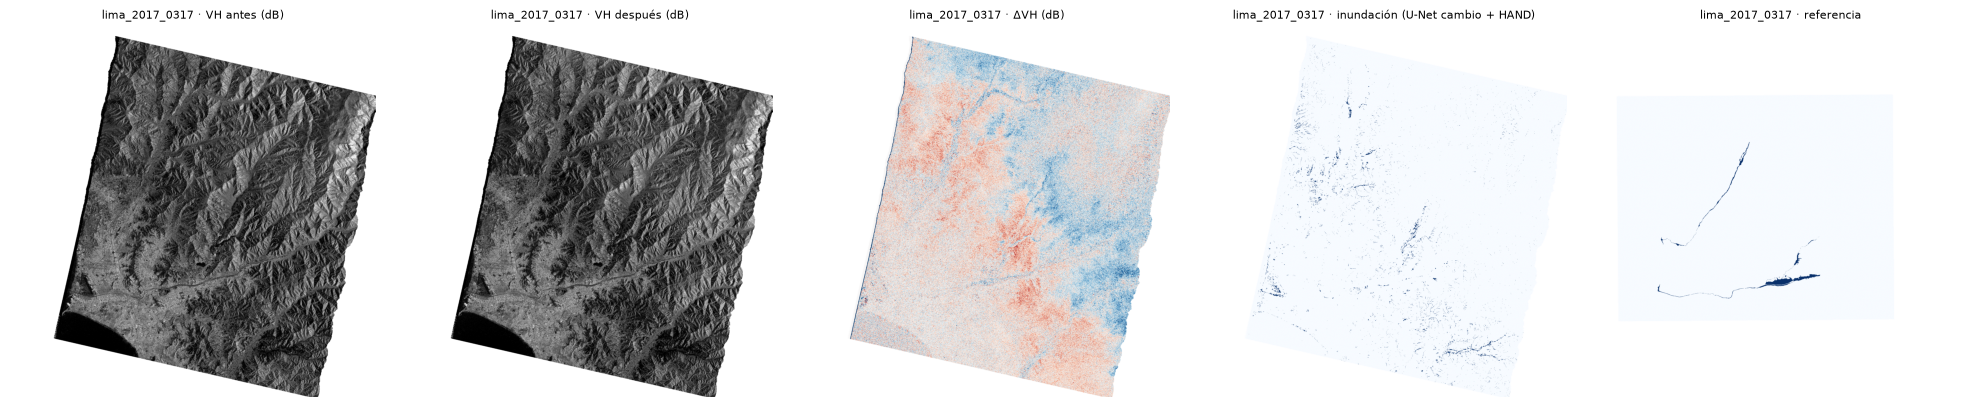

,metodo,agua_%,IoU,Dice,Precision,Recall,Accuracy
0,U-Net después + HAND<10,4.152,0.009,0.018,0.010,0.063,0.952
1,U-Net cambio + HAND<10,1.135,0.015,0.030,0.024,0.039,0.982
2,ΔVH<-3 dB + HAND<10,1.148,0.024,0.048,0.038,0.064,0.983
3,U-Net cambio + ΔVH<-3 dB + HAND<10,0.140,0.007,0.014,0.040,0.008,0.992


In [23]:
detectar_cambio(f"{LIMA}/lima_2017_0317.tif", f"{LIMA}/lima_2017_0305.tif", referencia=ref_2017)

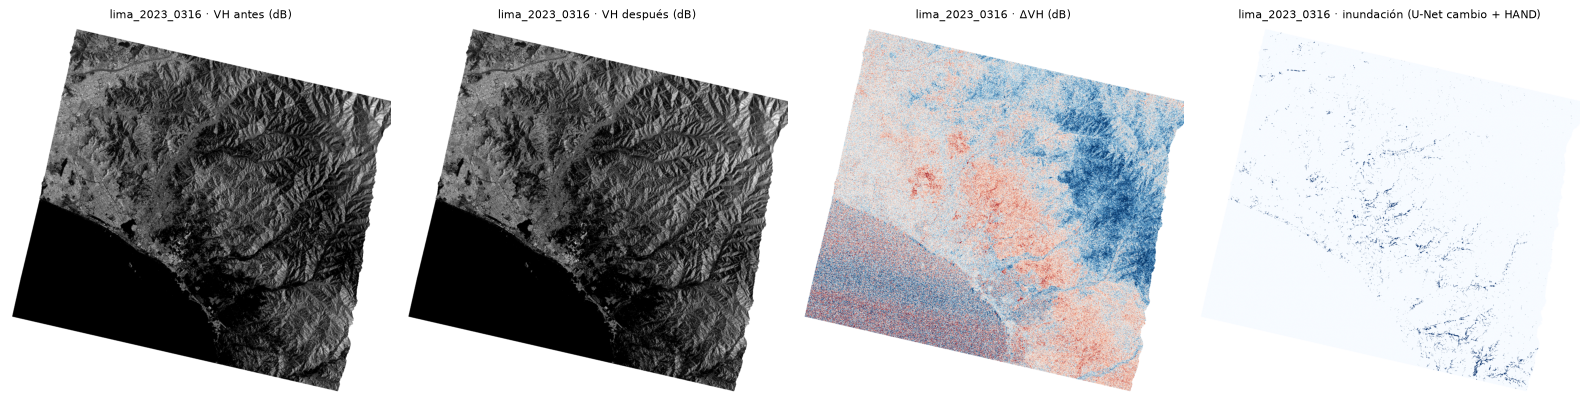

,metodo,agua_%
0,U-Net después + HAND<10,25.301
1,U-Net cambio + HAND<10,1.224
2,ΔVH<-3 dB + HAND<10,4.270
3,U-Net cambio + ΔVH<-3 dB + HAND<10,0.235


In [24]:
detectar_cambio(f"{LIMA}/lima_2023_0316.tif", f"{LIMA}/lima_2023_0304.tif")